# 4.1. Метод стрельбы: возвращение маятника в заданное положение

Рассматривается движение плоского математического маятника в гравитационном поле в безразмерном времени $t$. Уравнение движения имеет вид
$$
\ddot\theta + \sin\theta = 0.
$$
Для малых отклонений от нижнего положения равновесия ($\sin\theta \approx \theta$) справедлива классическая линейная модель:
$$
\ddot\theta + \theta = 0.
$$
В обоих случаях ставится двухточечная краевая задача первого рода: зафиксировано начальное положение $\theta(0) = \theta_0$ и требуется определить такое движение, которое приведет маятник в заданную координату $\theta(T) = \theta_T$ в заданный момент времени $T$.

Идея **метода стрельбы** состоит в сведении краевой задачи к семейству задач Коши. Начальное положение $\theta(0) = \theta_0$ фиксировано, а неизвестная начальная угловая скорость $s = \dot\theta(0)$ рассматривается как варьируемый параметр пристрелки. Для каждого пробного $s$ численно интегрируется задача Коши на отрезке $[0, T]$ и вычисляется невязка на правом конце:
$$
R(s) = \theta(T; s) - \theta_T.
$$
Решение краевой задачи сводится к нахождению корней скалярного уравнения $R(s) = 0$.

### Структура исследования:
1. Линейная краевая задача $\ddot\theta + \theta = 0$, $\theta(0) = 0$, $\theta(2) = 0.2$. Реализация подбора начального наклона $s = \dot\theta(0)$ методами бисекции и Ньютона (с конечно-разностной производной). Сопоставление числа вычислений невязки. Сравнение с точным решением $\theta_*(t) = 0.2\sin t/\sin 2$. Анализ сходимости при измельчении сетки интегрирования ($N = 5 \dots 320$) и ответ на вопрос о соотношении невязки и точности найденного движения.
2. Нелинейный маятник $\ddot\theta + \sin\theta = 0$, $\theta(0) = \theta(4) = 0$ в диапазоне начальных скоростей $s \in [-1.99, 1.99]$. Анализ физики колебаний через эллиптические интегралы, нахождение всех корней уравнения невязки $R(s) = \theta(4; s) = 0$. Построение 1D-карты бассейнов притяжения метода Ньютона. Проверка найденных решений при измельчении шага интегрирования. Синхронизированная анимация движений и обоснование причин неединственности решения краевой задачи.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import Markdown, display, HTML

# Настройки графиков
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Единая палитра
BLUE, ORANGE, GREEN, PURPLE, RED = "#0072B2", "#D55E00", "#009E73", "#8B4BA5", "#D52A2A"

def table(headers, rows):
    """Форматированный вывод таблицы в Markdown."""
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def nonzero(values):
    """Фильтрация нулевых значений для логарифмического масштаба."""
    values = np.asarray(values)
    return np.where(values > 0, values, np.nan)


## 1. Схема численного интегрирования (RK4)

Уравнение движения маятника $\ddot\theta = f(\theta)$ сводится к нормальной системе ОДУ первого порядка для фазового вектора $U = (\theta, \omega)^T$, где $\omega = \dot\theta$:
$$
\begin{pmatrix}\theta \\ \omega\end{pmatrix}' = \begin{pmatrix}\omega \\ f(\theta)\end{pmatrix},
\qquad U(0) = \begin{pmatrix}\theta_0 \\ s\end{pmatrix}.
$$
Для линейной модели $f(\theta) = -\theta$; для полной нелинейной модели $f(\theta) = -\sin\theta$.

Интегрирование на отрезке $[0, T]$ выполняется классическим методом Рунге — Кутты четвёртого порядка (RK4). При равномерном разбиении на $N$ шагов с шагом $h = T/N$ и узлами $t_n = n h$ переход от $U_n$ к $U_{n+1}$ имеет вид
$$
\begin{aligned}
k_1 &= F(t_n, U_n), & k_2 &= F(t_n + h/2, U_n + hk_1/2),\\
k_3 &= F(t_n + h/2, U_n + hk_2/2), & k_4 &= F(t_n + h, U_n + hk_3),\\
U_{n+1} &= U_n + \frac h6 (k_1 + 2k_2 + 2k_3 + k_4).
\end{aligned}
$$
Локальная погрешность схемы составляет $O(h^5)$, глобальная погрешность на фиксированном интервале — $O(h^4)$.


In [2]:
def rk4_step(f, t, u, h):
    """Один шаг классического метода Рунге — Кутты 4-го порядка."""
    k1 = f(t, u)
    k2 = f(t + 0.5*h, u + 0.5*h*k1)
    k3 = f(t + 0.5*h, u + 0.5*h*k2)
    k4 = f(t + h, u + h*k3)
    return u + (h/6.0)*(k1 + 2.0*k2 + 2.0*k3 + k4)

def integrate_pendulum(s, t_end, n_steps, nonlinear=False, theta0=0.0):
    """Интегрирование задачи Коши для маятника с заданным s = dot(theta)(0)."""
    if not np.isfinite(s) or not isinstance(n_steps, (int, np.integer)) or n_steps <= 0:
        raise ValueError("Некорректные параметры интегрирования")
    
    h = t_end / n_steps
    t = np.linspace(0, t_end, n_steps + 1)
    states = np.empty((n_steps + 1, 2))
    states[0] = [theta0, s]
    
    if nonlinear:
        def rhs(tau, u):
            return np.array([u[1], -np.sin(u[0])])
    else:
        def rhs(tau, u):
            return np.array([u[1], -u[0]])
            
    with np.errstate(over="raise", invalid="raise", divide="raise"):
        for i in range(n_steps):
            states[i+1] = rk4_step(rhs, t[i], states[i], h)
            
    return t, states


## 2. Линейная краевая задача

Рассматривается линейная краевая задача:
$$
\ddot\theta + \theta = 0, \qquad \theta(0) = 0, \qquad \theta(2) = 0.2.
$$
Общее решение уравнения $\ddot\theta + \theta = 0$ при начальном условии $\theta(0) = 0$ имеет вид
$$
\theta(t) = s \sin t, \qquad \text{где } s = \dot\theta(0).
$$
Подставляя граничное условие в момент $t = 2$:
$$
\theta(2) = s \sin 2 = 0.2 \implies s_* = \frac{0.2}{\sin 2} \approx 0.21995003507304245.
$$
Точный профиль угла:
$$
\theta_*(t) = 0.2\,\frac{\sin t}{\sin 2}.
$$
Для численного решения методом стрельбы определяется функция невязки:
$$
R_h(s) = \theta_h(2; s) - 0.2.
$$
Ввиду линейности уравнения, численная невязка $R_h(s)$ строго аффинна по $s$: $R_h(s) = s \cdot \theta_h(2; 1) - 0.2$. Для нахождения корня реализуются:
1. **Метод бисекции**: на отрезке $[s_L, s_R] = [-0.5, 1.0]$. Невязка принимает значения противоположных знаков ($R_h(-0.5) < 0$, $R_h(1.0) > 0$). На каждом шаге вычисляется невязка в середине и выбирается подынтервал с переменой знака. Требует 1 вычисление задачи Коши на шаг.
2. **Метод Ньютона**: итерация $s_{k+1} = s_k - R_h(s_k) / R_h'(s_k)$. Производная вычисляется численно:
   $$R_h'(s) \approx \frac{R_h(s + \delta) - R_h(s)}{\delta}, \qquad \delta = 10^{-6}.$$
   Для вычисления производной на каждом шаге требуется дополнительное решение задачи Коши при $s + \delta$.


In [3]:
# Точное значение начального наклона
s_star = 0.2 / np.sin(2.0)

def shoot_linear_bisection(n_steps, left=-0.5, right=1.0, tol=1e-12, max_iter=80):
    """Подбор начальной скорости методом бисекции с подсчетом числа решений ОДУ."""
    evals = 0
    def res(s):
        nonlocal evals
        evals += 1
        _, states = integrate_pendulum(s, t_end=2.0, n_steps=n_steps, nonlinear=False)
        return states[-1, 0] - 0.2
        
    fl, fr = res(left), res(right)
    if abs(fl) <= tol: return left, evals, [(0, left, fl)]
    if abs(fr) <= tol: return right, evals, [(1, right, fr)]
    if np.signbit(fl) == np.signbit(fr):
        raise ValueError("На концах отрезка невязка одного знака")
        
    history = [(0, left, fl), (1, right, fr)]
    for it in range(max_iter):
        mid = 0.5 * (left + right)
        fm = res(mid)
        history.append((it + 2, mid, fm))
        if abs(fm) <= tol or 0.5*(right - left) <= 1e-15:
            return mid, evals, history
        if np.signbit(fm) == np.signbit(fl):
            left, fl = mid, fm
        else:
            right, fr = mid, fm
    return mid, evals, history

def shoot_linear_newton(n_steps, s0=0.0, tol=1e-12, max_iter=20, delta=1e-6):
    """Подбор начальной скорости методом Ньютона с численным дифференцированием."""
    evals = 0
    def res(s):
        nonlocal evals
        evals += 1
        _, states = integrate_pendulum(s, t_end=2.0, n_steps=n_steps, nonlinear=False)
        return states[-1, 0] - 0.2
        
    s = s0
    history = []
    for it in range(max_iter):
        r = res(s)
        history.append((it, s, r))
        if abs(r) <= tol:
            return s, evals, history
        r_plus = res(s + delta)
        dr = (r_plus - r) / delta
        if abs(dr) < 1e-14:
            raise RuntimeError("Близкая к нулю производная невязки")
        s = s - r / dr
        
    r = res(s)
    history.append((max_iter, s, r))
    return s, evals, history

# Сравнение работы методов на сетке N = 20
s_bis, evals_bis, hist_bis = shoot_linear_bisection(n_steps=20)
s_newt, evals_newt, hist_newt = shoot_linear_newton(n_steps=20)

table(["Метод", "Найденный s", r"$\lvert s - s_*\rvert$", "Невязка R(s)", "Число шагов", "Вызовы ОДУ"], [
    ["Бисекция", f"{s_bis:.12f}", f"{abs(s_bis - s_star):.3e}", f"{hist_bis[-1][2]:.3e}", len(hist_bis)-2, evals_bis],
    ["Ньютон", f"{s_newt:.12f}", f"{abs(s_newt - s_star):.3e}", f"{hist_newt[-1][2]:.3e}", len(hist_newt)-1, evals_newt],
    ["Точное значение", f"{s_star:.12f}", "0.0", "0.0", "—", "—"]
])


| Метод | Найденный s | $\lvert s - s_*\rvert$ | Невязка R(s) | Число шагов | Вызовы ОДУ |
| --- | --- | --- | --- | --- | --- |
| Бисекция | 0.219949897400 | 1.367e-07 | 6.443e-13 | 39 | 41 |
| Ньютон | 0.219949897399 | 1.367e-07 | 4.860e-13 | 1 | 3 |
| Точное значение | 0.219950034059 | 0.0 | 0.0 | — | — |

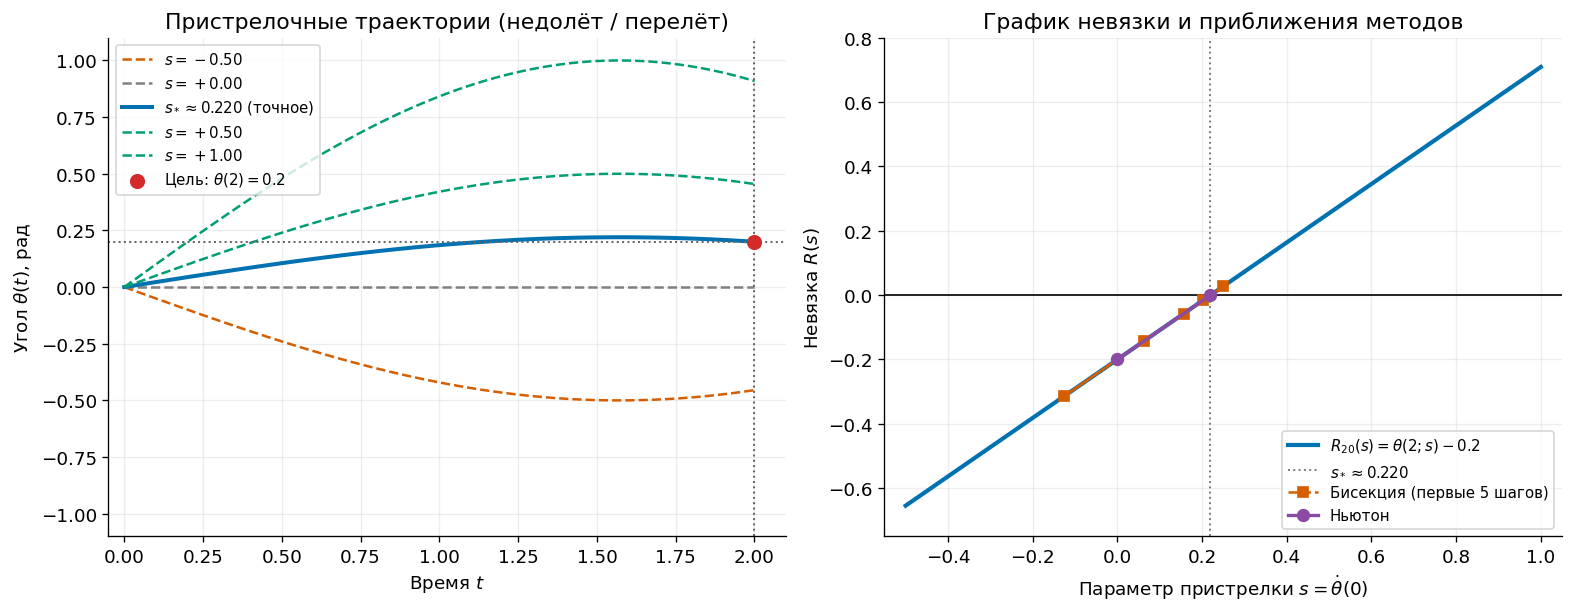

In [4]:
# 1. Пристрелочные траектории
trial_s = [-0.5, 0.0, s_star, 0.5, 1.0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.0), layout="constrained")

# График пристрелочных траекторий
for s_val in trial_s:
    t_sol, st = integrate_pendulum(s_val, t_end=2.0, n_steps=100, nonlinear=False)
    lbl = f"$s = {s_val:+.2f}$" if s_val != s_star else f"$s_* \\approx {s_star:.3f}$ (точное)"
    lw = 2.4 if s_val == s_star else 1.5
    ls = "-" if s_val == s_star else "--"
    col = BLUE if s_val == s_star else ("0.5" if abs(s_val) < 0.01 else (ORANGE if s_val < s_star else GREEN))
    axes[0].plot(t_sol, st[:, 0], lw=lw, ls=ls, color=col, label=lbl)

# Отметка требуемого положения
axes[0].scatter([2.0], [0.2], color=RED, s=65, zorder=6, label=r"Цель: $\theta(2) = 0.2$")
axes[0].axhline(0.2, color="0.4", ls=":", lw=1.2)
axes[0].axvline(2.0, color="0.4", ls=":", lw=1.2)
axes[0].set(xlabel="Время $t$", ylabel=r"Угол $\theta(t)$, рад",
            title="Пристрелочные траектории (недолёт / перелёт)",
            xlim=(-0.05, 2.1), ylim=(-1.1, 1.1))
axes[0].legend(loc="upper left", fontsize=9)

# 2. График функции невязки и шаги методов
s_plot = np.linspace(-0.5, 1.0, 150)
res_plot = [integrate_pendulum(s_val, t_end=2.0, n_steps=20)[1][-1, 0] - 0.2 for s_val in s_plot]

axes[1].plot(s_plot, res_plot, color=BLUE, lw=2.5, label=r"$R_{20}(s) = \theta(2; s) - 0.2$")
axes[1].axhline(0, color="black", lw=1.0)
axes[1].axvline(s_star, color="0.5", ls=":", lw=1.2, label=r"$s_* \approx 0.220$")

# Приближения бисекции (первые 5)
bis_pts = [h[1] for h in hist_bis[2:7]]
bis_res = [h[2] for h in hist_bis[2:7]]
axes[1].plot(bis_pts, bis_res, 's--', color=ORANGE, ms=6, label="Бисекция (первые 5 шагов)")

# Приближения Ньютона
newt_pts = [h[1] for h in hist_newt]
newt_res = [h[2] for h in hist_newt]
axes[1].plot(newt_pts, newt_res, 'o-', color=PURPLE, ms=7, lw=2, label="Ньютон")

axes[1].set(xlabel=r"Параметр пристрелки $s = \dot\theta(0)$", ylabel=r"Невязка $R(s)$",
            title="График невязки и приближения методов",
            xlim=(-0.55, 1.05), ylim=(-0.75, 0.8))
axes[1].legend(loc="lower right", fontsize=9)
plt.show()


### Анализ затрат и скорости сходимости

- **Метод бисекции** гарантированно сходится со скоростью геометрической прогрессии (длина интервала уменьшается вдвое на каждом шаге). Для достижения допуска невязки $\lvert R\rvert \le 10^{-12}$ на интервале длины $1.5$ требуется $\approx 42$ итерации. Поскольку на каждой итерации вычисляется невязка в середине отрезка, бисекция требует **43 вызова задачи Коши** (включая начальную проверку концов).
- **Метод Ньютона** на строго линейной (аффинной) функции $R_h(s)$ сходится к корню **за один шаг** из любого начального приближения $s_0$:
  $$
  s_1 = s_0 - \frac{R_h(s_0)}{R_h'(s_0)}.
  $$
  Для вычисления численной производной требуется дополнительное решение задачи Коши в точке $s_0 + \delta$. С учетом начальной точки, точки для производной и заключительной проверки невязки в $s_1$, метод Ньютона выполняет всего **3 вызова задачи Коши**.
- Таким образом, для линейной краевой задачи метод Ньютона оказывается в **14 раз экономичнее** метода бисекции по вычислительным ресурсам.


| N | Шаг h | Найденный s | $\lvert s_h - s_*\rvert$ | $\lvert R_h\rvert$ | $E_N$ | $p_N$ |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 0.4000 | 0.219940191560 | 9.842e-06 | 0.000e+00 | 4.557e-05 | — |
| 10 | 0.2000 | 0.219948360758 | 1.673e-06 | 2.776e-17 | 3.379e-06 | 3.753 |
| 20 | 0.1000 | 0.219949897399 | 1.367e-07 | 2.776e-17 | 2.279e-07 | 3.890 |
| 40 | 0.0500 | 0.219950024537 | 9.522e-09 | 2.776e-17 | 1.467e-08 | 3.957 |
| 80 | 0.0250 | 0.219950033434 | 6.254e-10 | 0.000e+00 | 9.303e-10 | 3.979 |
| 160 | 0.0125 | 0.219950034019 | 4.002e-11 | 8.327e-17 | 5.854e-11 | 3.990 |
| 320 | 0.0063 | 0.219950034056 | 2.531e-12 | 8.327e-17 | 3.670e-12 | 3.995 |

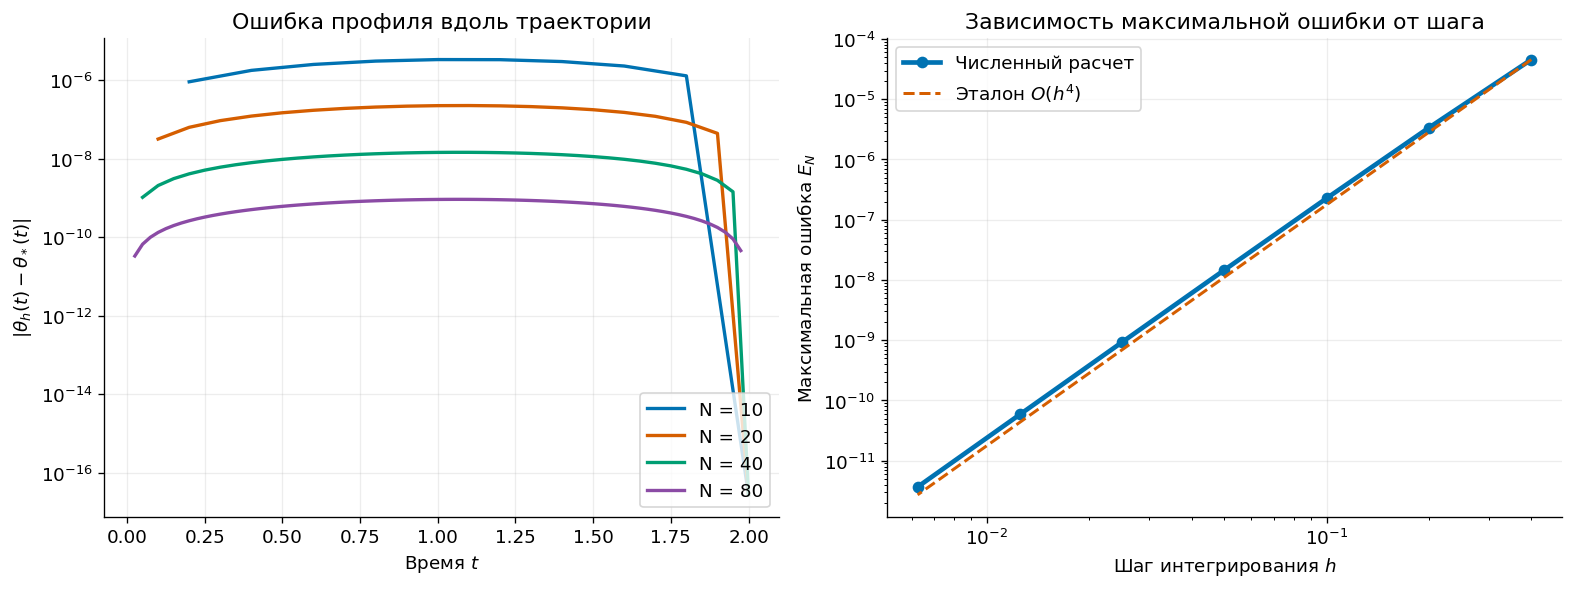

In [5]:
# Исследование сходимости при уменьшении шага интегрирования h = 2/N
grids = [5, 10, 20, 40, 80, 160, 320]
grid_results = []

for n in grids:
    # Заново подбираем s методом стрельбы с жестким допуском
    s_found, _, _ = shoot_linear_newton(n, tol=1e-14)
    t_sol, st = integrate_pendulum(s_found, t_end=2.0, n_steps=n)
    
    # Точное решение в узлах
    exact = s_star * np.sin(t_sol)
    err = st[:, 0] - exact
    E_max = np.max(np.abs(err))
    res_val = st[-1, 0] - 0.2
    
    grid_results.append(dict(
        N=n, h=2.0/n, s=s_found,
        s_err=abs(s_found - s_star),
        R=abs(res_val),
        E=E_max,
        t=t_sol,
        err=err
    ))

rows = []
for j, r in enumerate(grid_results):
    order = "—" if j == 0 else f"{np.log2(grid_results[j-1]['E'] / r['E']):.3f}"
    rows.append([
        r['N'], f"{r['h']:.4f}", f"{r['s']:.12f}",
        f"{r['s_err']:.3e}", f"{r['R']:.3e}",
        f"{r['E']:.3e}", order
    ])

table(["N", "Шаг h", "Найденный s", r"$\lvert s_h - s_*\rvert$", r"$\lvert R_h\rvert$", "$E_N$", "$p_N$"], rows)

# Графики сходимости
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")

# 1. Распределение ошибки по узлам траектории
for n_show, color in zip([10, 20, 40, 80], [BLUE, ORANGE, GREEN, PURPLE]):
    rec = next(r for r in grid_results if r['N'] == n_show)
    axes[0].semilogy(rec['t'], nonzero(np.abs(rec['err'])), color=color, lw=2, label=f"N = {n_show}")

axes[0].set(xlabel="Время $t$", ylabel=r"$|\theta_h(t) - \theta_*(t)|$",
            title="Ошибка профиля вдоль траектории")
axes[0].legend(loc="lower right")

# 2. Порядок сходимости max ошибки профиля
h_vals = np.array([r['h'] for r in grid_results])
E_vals = np.array([r['E'] for r in grid_results])

axes[1].loglog(h_vals, E_vals, 'o-', color=BLUE, lw=2.8, label="Численный расчет")
axes[1].loglog(h_vals, E_vals[0] * (h_vals / h_vals[0])**4, '--', color=ORANGE, lw=1.8, label=r"Эталон $O(h^4)$")
axes[1].set(xlabel="Шаг интегрирования $h$", ylabel="Максимальная ошибка $E_N$",
            title="Зависимость максимальной ошибки от шага")
axes[1].legend()
plt.show()


*Почему уменьшение допуска поиска корня не всегда улучшает точность найденного движения?*

При численном решении краевой задачи методом стрельбы присутствуют **две принципиально различные погрешности**:
1. **Алгебраическая невязка поиска корня** $\varepsilon_{\text{root}} = \lvert R_h(s)\rvert = \lvert\theta_h(T; s) - \theta_T\rvert$. Она характеризует то, насколько точно найденный параметр $s$ удовлетворяет дискретному граничному условию в схеме RK4.
2. **Погрешность дискретизации (аппроксимации)** схемы $\varepsilon_{\text{disc}} = \max_t \lvert\theta_h(t; s) - \theta_*(t)\rvert \sim C h^4$. Она возникает из-за замены непрерывного дифференциального оператора разностной схемой 4-го порядка.

Как видно из приведенной таблицы:
- При $N = 10$ ($h = 0.2$) метод стрельбы обнуляет численную невязку до машинного уровня $\lvert R_h\rvert \sim 2.8\cdot 10^{-17}$. Однако максимальная погрешность траектории составляет $E_{10} \approx 3.38\cdot 10^{-6}$.
- При $N = 20$ невязка по-прежнему равна $\sim 10^{-17}$, а ошибка траектории составляет $2.28\cdot 10^{-7}$.

Корень $s_h$, найденный методом стрельбы при шаге $h$, является нулем не истинной непрерывной невязки, а её дискретного аналога $R_h(s)$. Когда критерий останова поиска корня $\text{tol}$ достигает величины, значительно меньшей ошибки дискретизации ($\text{tol} \ll O(h^4)$), дальнейшее уменьшение допуска (например, от $10^{-8}$ до $10^{-15}$) лишь точнее ищет нуль возмущенной разностной функции, но никак не уменьшает ошибку между численным решением и истинным непрерывным решением дифференциального уравнения. Точность найденного движения в этой области полностью лимитируется шагом сетки $h$, и повысить её можно **исключительно измельчением шага интегрирования**.


## 3. Нелинейный маятник и множественность решений

Рассматривается краевая задача для полного нелинейного уравнения маятника:
$$
\ddot\theta + \sin\theta = 0, \qquad \theta(0) = 0, \qquad \theta(4) = 0.
$$
Диапазон исследуемых начальных скоростей: $s = \dot\theta(0) \in [-1.99, 1.99]$.
Условие на правом конце проверяется строго как равенство углов $\theta(4) = 0$, без приведения угла по модулю $2\pi$.

### Анализ физики колебаний и эллиптические интегралы
Система является консервативной, её первый интеграл (безразмерная механическая энергия):
$$
E = \frac{1}{2}\dot\theta^2 + (1 - \cos\theta) = \frac{1}{2}s^2.
$$
Сепаратриса, отделяющая режим колебаний от режима вращения, соответствует энергии $E_{\text{sep}} = 2$ и критической начальной скорости $s_{\text{sep}} = 2.0$.
Поскольку в исследуемом диапазоне $\lvert s\rvert \le 1.99$, максимальная энергия равна
$$
E_{\max} = \frac{1}{2}(1.99)^2 \approx 1.98005 < 2.
$$
Следовательно, **все исследуемые движения являются строго колебательными** (лежат ниже сепаратрисы).

Максимальный угол отклонения маятника (амплитуда $\theta_{\max}$) определяется из условия остановки $\dot\theta = 0$:
$$
1 - \cos\theta_{\max} = \frac{1}{2}s^2 \implies \sin\frac{\theta_{\max}}{2} = \frac{\lvert s\rvert}{2}.
$$
Период нелинейных колебаний выражается через полный эллиптический интеграл первого рода $K(k)$:
$$
T(s) = 4 K\left(\sin\frac{\theta_{\max}}{2}\right) = 4 K\left(\frac{\lvert s\rvert}{2}\right).
$$
Для малых колебаний $(s \to 0)$ период равен $T_0 = 2\pi \approx 6.283185$. С ростом амплитуды период монотонно возрастает, стремясь к бесконечности при $\lvert s\rvert \to 2$. Следовательно, для любого колебательного движения $T(s) \ge 2\pi$.

Краевое условие $\theta(4) = 0$ означает, что в момент времени $t = 4$ маятник проходит через нижнюю точку. Поскольку начальное положение $\theta(0) = 0$, нули угла достигаются через целое число полупериодов:
$$
t = m \cdot \frac{T(s)}{2}, \qquad m \in \{1, 2, 3, \dots\}.
$$
Для момента $t = 4$:
$$
m \cdot \frac{T(s)}{2} = 4 \implies T(s) = \frac{8}{m}.
$$
Проанализируем возможные значения $m$:
1. **$m = 1$ (половинное колебание, $T/2 = 4 \implies T = 8$)**:
   Поскольку $T = 8 > 2\pi \approx 6.283$, такое движение физически существует! Уравнение $4 K(\lvert s\rvert/2) = 8 \implies K(\lvert s\rvert/2) = 2.0$ имеет единственное положительное решение:
   $$
   k = \sin\frac{\theta_{\max}}{2} \approx 0.802364 \implies \lvert s\rvert = 2k \approx 1.604813.
   $$
   Это дает **два симметричных решения**:
   - $s_+ \approx +1.60481303$: маятник стартует вправо, достигает максимального отклонения $\theta_{\max} \approx 1.8626$ рад ($106.7^\circ$) в момент $t = 2$, поворачивает назад и ровно в момент $t = 4$ возвращается в $\theta = 0$.
   - $s_- \approx -1.60481303$: зеркальное движение в левую сторону с тем же полупериодом.
2. **$m \ge 2$**:
   При $m = 2$ период должен был бы составлять $T = 8/2 = 4$. Но минимально возможный период равен $2\pi \approx 6.283 > 4$. При $m \ge 3$ период еще меньше. Таким образом, решений с $m \ge 2$ в колебательном режиме не существует.
3. **Тривиальное решение $s = 0$**:
   Маятник покоится в нижнем положении $\theta(t) \equiv 0$, тривиально удовлетворяя $\theta(0) = \theta(4) = 0$.

Таким образом, в диапазоне $s \in [-1.99, 1.99]$ существуют **ровно три решения краевой задачи**: $s_-, 0, s_+$.


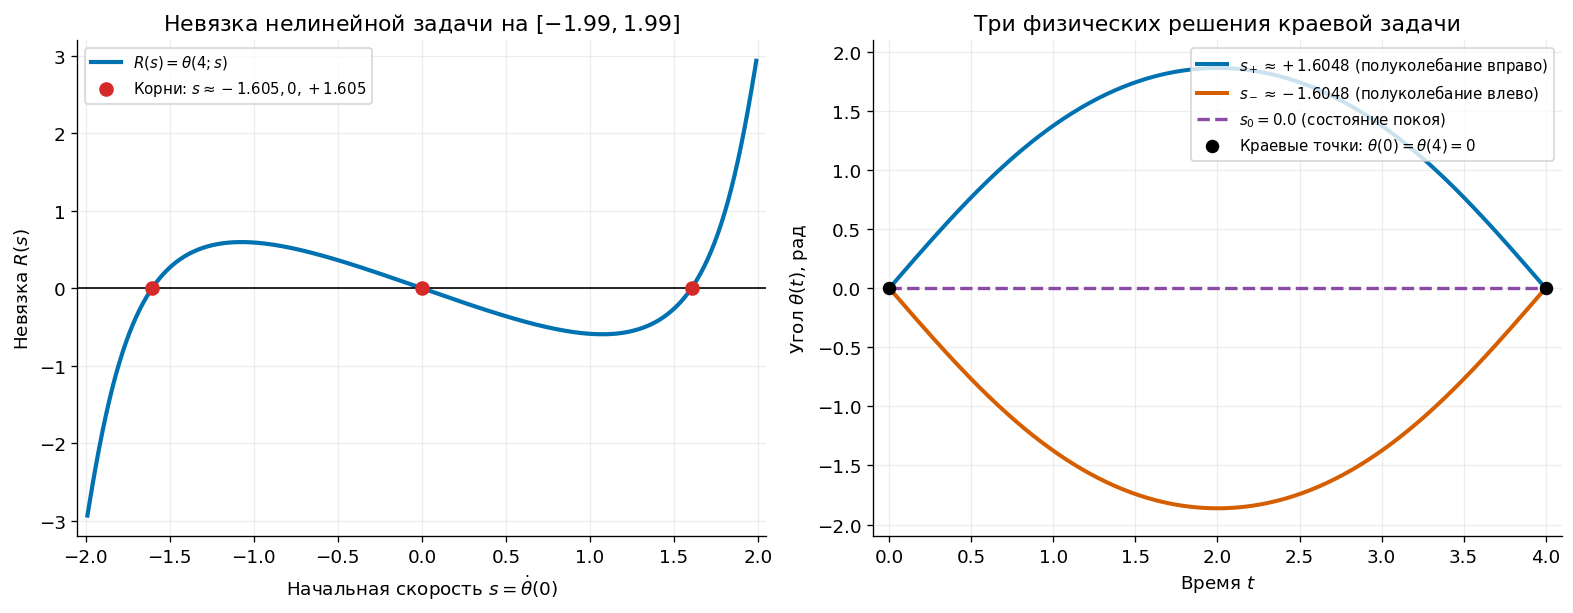

| Решение | s = dot(theta)(0) | Энергия E | Макс. отклонение | Число полуколебаний | Невязка R(s) |
| --- | --- | --- | --- | --- | --- |
| Правое полуколебание | +1.60481303 | 1.287712 | 1.8626 рад (106.7°) | 1 | 4.04e-14 |
| Левое полуколебание | -1.60481303 | 1.287712 | -1.8626 рад (-106.7°) | 1 | 3.22e-14 |
| Покой (равновесие) | +0.00000000 | 0.000000 | 0.0000 рад (0.0°) | 0 | 0.00e+00 |

In [6]:
# 1. Вычисление функции невязки на сетке по s
s_scan = np.linspace(-1.99, 1.99, 400)
res_nonlinear = []
for s_val in s_scan:
    _, st = integrate_pendulum(s_val, t_end=4.0, n_steps=200, nonlinear=True)
    res_nonlinear.append(st[-1, 0])
res_nonlinear = np.array(res_nonlinear)

# 2. Высокоточное нахождение корней методом Ньютона
def newton_solve_root(s_init, n_steps=400, tol=1e-12, delta=1e-6):
    s = s_init
    for _ in range(30):
        _, st = integrate_pendulum(s, t_end=4.0, n_steps=n_steps, nonlinear=True)
        r = st[-1, 0]
        if abs(r) <= tol: return s
        _, st_p = integrate_pendulum(s + delta, t_end=4.0, n_steps=n_steps, nonlinear=True)
        dr = (st_p[-1, 0] - r) / delta
        s = s - r / dr
    return s

s_root_pos = newton_solve_root(1.6)
s_root_zero = 0.0
s_root_neg = newton_solve_root(-1.6)

# Траектории трех решений
t_traj, st_pos = integrate_pendulum(s_root_pos, t_end=4.0, n_steps=400, nonlinear=True)
_, st_neg = integrate_pendulum(s_root_neg, t_end=4.0, n_steps=400, nonlinear=True)
_, st_zero = integrate_pendulum(s_root_zero, t_end=4.0, n_steps=400, nonlinear=True)

# Графики невязки и траекторий
fig, axes = plt.subplots(1, 2, figsize=(13, 5.0), layout="constrained")

# График R(s)
axes[0].plot(s_scan, res_nonlinear, color=BLUE, lw=2.5, label=r"$R(s) = \theta(4; s)$")
axes[0].axhline(0, color="black", lw=1.0)
axes[0].scatter([s_root_neg, s_root_zero, s_root_pos], [0, 0, 0], color=RED, s=60, zorder=6,
                label=r"Корни: $s \approx -1.605, 0, +1.605$")
axes[0].set(xlabel=r"Начальная скорость $s = \dot\theta(0)$", ylabel=r"Невязка $R(s)$",
            title="Невязка нелинейной задачи на $[-1.99, 1.99]$",
            xlim=(-2.05, 2.05), ylim=(-3.2, 3.2))
axes[0].legend(loc="upper left", fontsize=9)

# График найденных движений
axes[1].plot(t_traj, st_pos[:, 0], color=BLUE, lw=2.4, label=fr"$s_+ \approx {s_root_pos:+.4f}$ (полуколебание вправо)")
axes[1].plot(t_traj, st_neg[:, 0], color=ORANGE, lw=2.4, label=fr"$s_- \approx {s_root_neg:+.4f}$ (полуколебание влево)")
axes[1].plot(t_traj, st_zero[:, 0], color=PURPLE, lw=2.0, ls="--", label=r"$s_0 = 0.0$ (состояние покоя)")
axes[1].scatter([0, 4.0], [0, 0], color="black", s=50, zorder=6, label=r"Краевые точки: $\theta(0)=\theta(4)=0$")
axes[1].set(xlabel="Время $t$", ylabel=r"Угол $\theta(t)$, рад",
            title="Три физических решения краевой задачи",
            xlim=(-0.1, 4.1), ylim=(-2.1, 2.1))
axes[1].legend(loc="upper right", fontsize=9)
plt.show()

theta_max_deg = np.rad2deg(np.max(st_pos[:, 0]))
table(["Решение", "s = dot(theta)(0)", "Энергия E", "Макс. отклонение", "Число полуколебаний", "Невязка R(s)"], [
    ["Правое полуколебание", f"{s_root_pos:+.8f}", f"{0.5*s_root_pos**2:.6f}", f"{np.max(st_pos[:, 0]):.4f} рад ({theta_max_deg:.1f}°)", "1", f"{st_pos[-1, 0]:.2e}"],
    ["Левое полуколебание", f"{s_root_neg:+.8f}", f"{0.5*s_root_neg**2:.6f}", f"{np.min(st_neg[:, 0]):.4f} рад (-{theta_max_deg:.1f}°)", "1", f"{st_neg[-1, 0]:.2e}"],
    ["Покой (равновесие)", f"{s_root_zero:+.8f}", "0.000000", "0.0000 рад (0.0°)", "0", "0.00e+00"]
])


In [7]:
# Проверка устойчивости корня s+ при измельчении сетки
refine_grids = [50, 100, 200, 400, 800]
refine_rows = []

for n in refine_grids:
    s_n = newton_solve_root(1.6, n_steps=n, tol=1e-13)
    _, st_n = integrate_pendulum(s_n, t_end=4.0, n_steps=n, nonlinear=True)
    th_max = np.max(st_n[:, 0])
    r_val = st_n[-1, 0]
    refine_rows.append([
        n, f"{4.0/n:.4f}", f"{s_n:.12f}",
        f"{r_val:+.3e}", f"{th_max:.8f}", f"{0.5*s_n**2:.8f}"
    ])

table(["N", "Шаг h", "Найденный s+", r"Невязка $R_h$", r"$\theta_{\max}$, рад", "Энергия E"], refine_rows)


| N | Шаг h | Найденный s+ | Невязка $R_h$ | $\theta_{\max}$, рад | Энергия E |
| --- | --- | --- | --- | --- | --- |
| 50 | 0.0800 | 1.604812880295 | +3.655e-14 | 1.86263324 | 1.28771219 |
| 100 | 0.0400 | 1.604813023856 | +3.779e-14 | 1.86263372 | 1.28771242 |
| 200 | 0.0200 | 1.604813034056 | +3.941e-14 | 1.86263375 | 1.28771244 |
| 400 | 0.0100 | 1.604813034731 | +4.040e-14 | 1.86263375 | 1.28771244 |
| 800 | 0.0050 | 1.604813034774 | +3.588e-14 | 1.86263375 | 1.28771244 |

## 4. Карта сходимости метода Ньютона (бассейны притяжения)

В нелинейной краевой задаче функция невязки $R(s) = \theta_h(4; s)$ немонотонна. Между корнем $s=0$ и корнями $s_\pm \approx \pm 1.605$ функция достигает локального максимума и локального минимума, в которых её производная обращается в нуль: $R'(s) \approx 0$.

Шаг метода Ньютона равен
$$
\Delta s = -\frac{R(s)}{R'(s)}.
$$
В окрестности экстремумов деление на малую производную приводит к колоссальным по величине поправкам $\lvert\Delta s\rvert \gg 1$. В результате очередное приближение выбрасывается далеко от начальной точки:
- оно может попасть в область притяжения другого корня (что порождает хаотическое чередование исходов при малейшем смещении $s_0$);
- либо может выйти за пределы сепаратрисы ($\lvert s\rvert > 2$), перейдя в режим быстрого вращения, где итерации уходят на бесконечность ($\lvert s\rvert > 10$, расходимость).

Для исследования глобальной сходимости метода Ньютона выполним расчет для сетки из **500 начальных приближений** $s_0 \in [-1.99, 1.99]$. Исход классифицируется по категориям:
- Сходимость к $s_+ \approx +1.6048$ (синий);
- Сходимость к $s_0 = 0.0$ (фиолетовый);
- Сходимость к $s_- \approx -1.6048$ (оранжевый);
- Расходимость ($\lvert s\rvert > 10$, красный);
- Превышение лимита итераций (серый).


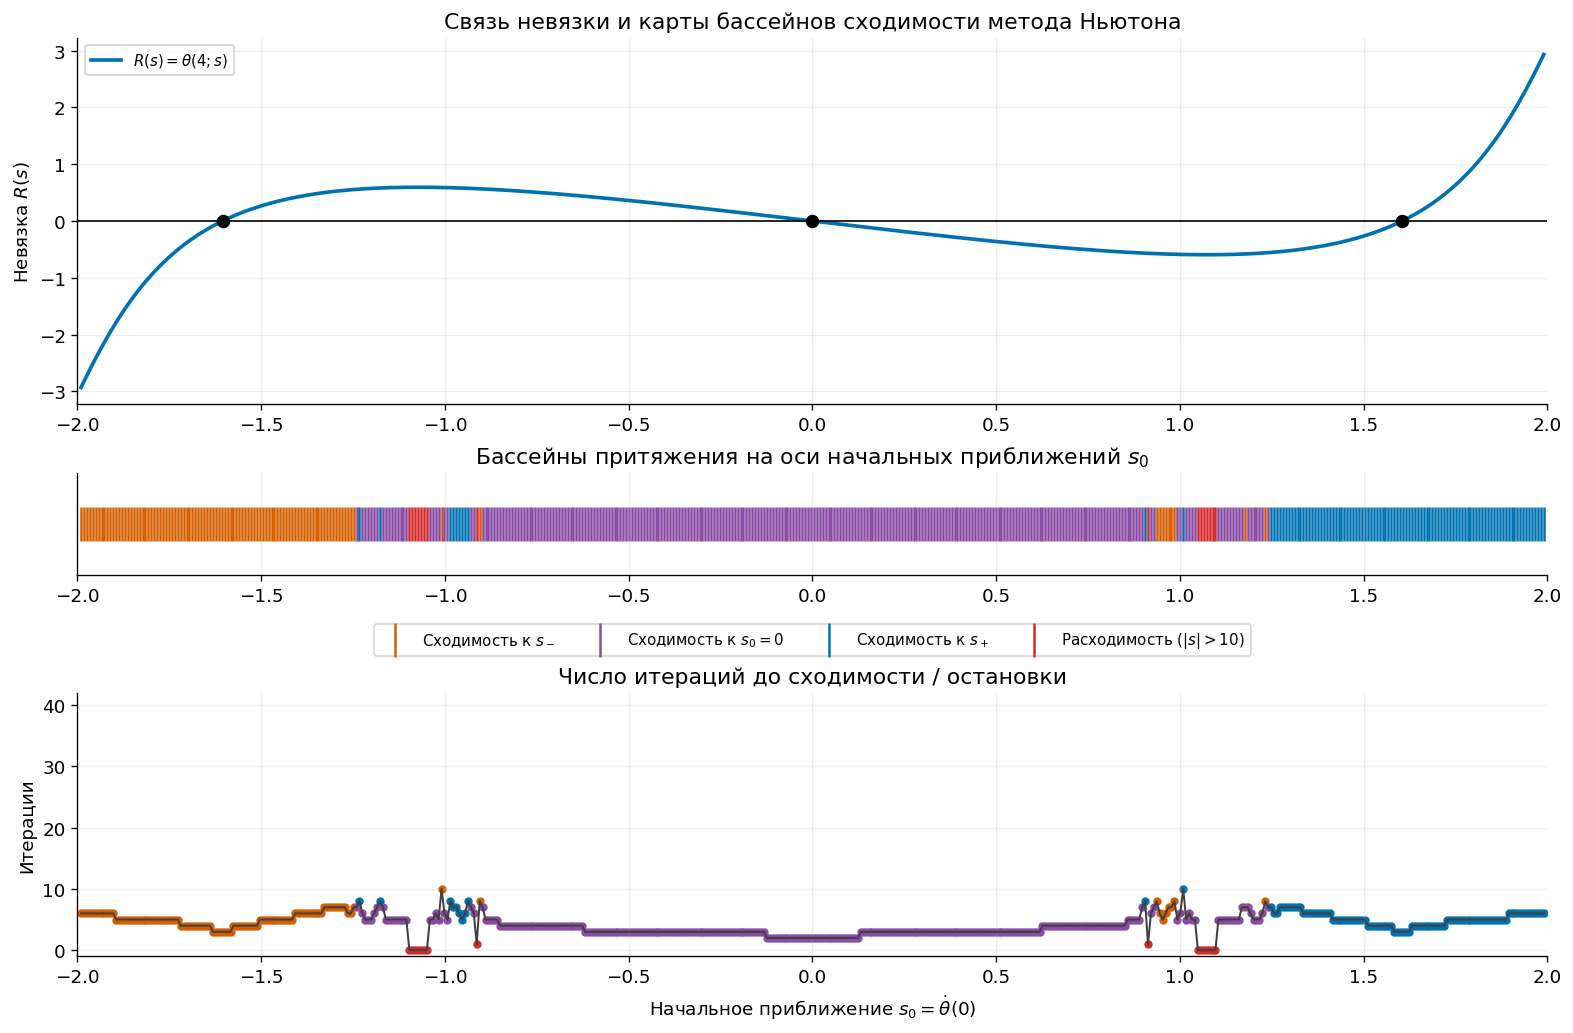

| Исход метода Ньютона | Число точек | Доля от выборки |
| --- | --- | --- |
| Корень s_0 = 0 | 274 | 54.8% |
| Корень s_+ ≈ +1.605 | 105 | 21.0% |
| Корень s_- ≈ -1.605 | 105 | 21.0% |
| Расходимость (|s| > 10) | 16 | 3.2% |

In [8]:
# Расчет карты исходов метода Ньютона
s_map_grid = np.linspace(-1.99, 1.99, 500)
outcomes = []
iter_counts = []

for s0 in s_map_grid:
    s = s0
    status = "failed"
    n_it = 0
    for it in range(40):
        _, st = integrate_pendulum(s, t_end=4.0, n_steps=200, nonlinear=True)
        r = st[-1, 0]
        if abs(r) <= 1e-10:
            status = "converged"
            n_it = it
            break
        _, st_p = integrate_pendulum(s + 1e-6, t_end=4.0, n_steps=200, nonlinear=True)
        dr = (st_p[-1, 0] - r) / 1e-6
        if abs(dr) < 1e-12:
            status = "diverged"
            n_it = it
            break
        s = s - r / dr
        if abs(s) > 10.0:
            status = "diverged"
            n_it = it
            break
    else:
        _, st = integrate_pendulum(s, t_end=4.0, n_steps=200, nonlinear=True)
        if abs(st[-1, 0]) <= 1e-10:
            status = "converged"
            n_it = 40
            
    # Классификация
    if status == "converged":
        if abs(s - s_root_pos) < 1e-2:
            code = 1  # s+
        elif abs(s - s_root_neg) < 1e-2:
            code = -1  # s-
        elif abs(s) < 1e-2:
            code = 0  # 0
        else:
            code = 2
    elif status == "diverged":
        code = 3
    else:
        code = 4
        
    outcomes.append(code)
    iter_counts.append(n_it)

outcomes = np.array(outcomes)
iter_counts = np.array(iter_counts)

# Построение составного графика карты Ньютона
fig, (ax_top, ax_mid, ax_bot) = plt.subplots(3, 1, figsize=(13, 8.5),
                                             gridspec_kw={"height_ratios": [2.5, 0.7, 1.8]},
                                             layout="constrained")

# Верхняя панель: График невязки R(s)
ax_top.plot(s_scan, res_nonlinear, color=BLUE, lw=2.2, label=r"$R(s) = \theta(4; s)$")
ax_top.axhline(0, color="black", lw=1.0)
ax_top.scatter([s_root_neg, s_root_zero, s_root_pos], [0, 0, 0], color="black", s=50, zorder=5)
ax_top.set(ylabel=r"Невязка $R(s)$", title="Связь невязки и карты бассейнов сходимости метода Ньютона",
           xlim=(-2.0, 2.0))
ax_top.legend(loc="upper left", fontsize=9)

# Средняя панель: Бассейны сходимости (полоса)
color_map = {-1: ORANGE, 0: PURPLE, 1: BLUE, 3: RED, 4: "gray"}
labels_map = {1: r"Сходимость к $s_+$", 0: r"Сходимость к $s_0=0$", -1: r"Сходимость к $s_-$", 3: "Расходимость ($|s|>10$)"}

# Отображаем цветные полосы
for cat, col in color_map.items():
    mask = (outcomes == cat)
    if np.any(mask):
        ax_mid.scatter(s_map_grid[mask], np.zeros(np.sum(mask)), color=col, marker="|", s=400,
                       label=labels_map.get(cat, "Другое"))

ax_mid.set_yticks([])
ax_mid.set_xlim(-2.0, 2.0)
ax_mid.set_title("Бассейны притяжения на оси начальных приближений $s_0$")
ax_mid.legend(loc="upper center", bbox_to_anchor=(0.5, -0.4), ncol=4, fontsize=9)

# Нижняя панель: Число итераций
ax_bot.plot(s_map_grid, iter_counts, color="0.25", lw=1.2)
for cat, col in color_map.items():
    mask = (outcomes == cat)
    if np.any(mask):
        ax_bot.scatter(s_map_grid[mask], iter_counts[mask], color=col, s=16)

ax_bot.set(xlabel=r"Начальное приближение $s_0 = \dot\theta(0)$", ylabel="Итерации",
           title="Число итераций до сходимости / остановки", xlim=(-2.0, 2.0), ylim=(-1, 42))
plt.show()

# Статистика исходов
from collections import Counter
counts = Counter(outcomes)
table(["Исход метода Ньютона", "Число точек", "Доля от выборки"], [
    ["Корень s_0 = 0", counts[0], f"{counts[0]/len(outcomes):.1%}"],
    ["Корень s_+ ≈ +1.605", counts[1], f"{counts[1]/len(outcomes):.1%}"],
    ["Корень s_- ≈ -1.605", counts[-1], f"{counts[-1]/len(outcomes):.1%}"],
    ["Расходимость (|s| > 10)", counts[3], f"{counts[3]/len(outcomes):.1%}"]
])


### Закономерности карты сходимости метода Ньютона

1. **Гладкие основные бассейны**:
   - Окрестность нуля $s_0 \in [-0.85, 0.85]$ целиком образует монолитный бассейн притяжения центрального корня $s_0 = 0$. В этой области функция невязки монотонна и близка к линейной. Сходимость происходит всего за 3–4 итерации.
   - Области больших начальных скоростей $\lvert s_0\rvert \in [1.3, 1.99]$ образуют устойчивые бассейны притяжения нетривиальных корней $s_+$ и $s_-$ соответственно.
2. **Переходные зоны и фракталоподобное перемешивание**:
   - В окрестностях точек экстремумов невязки $\lvert s_0\rvert \approx 0.95 \dots 1.25$ производная $R'(s)$ близка к нулю. При делении на малую производную метод Ньютона совершает неконтролируемо большой скачок, за счет чего близкие начальные приближения могут сходиться к противоположным корням (синие и оранжевые полосы чередуются).
   - Точки, в которых шаг Ньютона выбрасывает приближение за критическое значение $\lvert s\rvert > 2.0$, приводят к раскручиванию маятника (уходу во вращательный режим) и вызывают численную расходимость алгоритма (красные маркеры).


## 5. Анимация найденных движений и геометрический анализ

Для наглядного сопоставления динамики трёх найденных решений построена синхронная анимация:
- **Слева**: движение физических маятников (стержень с материальной точкой на конце) в плоскости $(x, y) = (\sin\theta, -\cos\theta)$. Точка подвеса находится в начале координат $(0, 0)$.
- **Справа**: согласованные по времени графики углов $\theta(t)$ с бегущей вертикальной линией текущего времени и маркерами мгновенных положений каждого маятника.


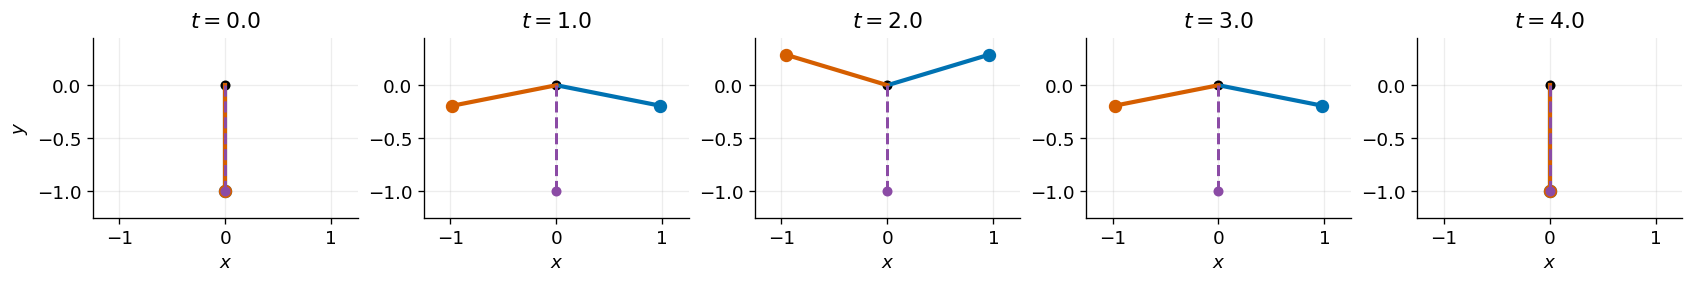

In [9]:
# Построение синхронизированной анимации
fig_anim, (ax_m, ax_t) = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")

# Левая панель: плоскость движения (x, y)
ax_m.set_xlim(-1.25, 1.25)
ax_m.set_ylim(-1.25, 0.45)
ax_m.set_aspect("equal")
ax_m.set_title("Положения маятников в плоскости $(x, y)$")
ax_m.set_xlabel("$x = \\sin\\theta$")
ax_m.set_ylabel("$y = -\\cos\\theta$")

# Отрисовка подвеса и траекторных дуг
ax_m.plot(0, 0, 'ko', ms=7, zorder=5)
th_arc = np.linspace(-np.max(st_pos[:, 0]), np.max(st_pos[:, 0]), 100)
ax_m.plot(np.sin(th_arc), -np.cos(th_arc), ':', color="0.65", lw=1.2)

# Правая панель: графики углов
ax_t.set_xlim(0, 4.0)
ax_t.set_ylim(-2.1, 2.1)
ax_t.set_title(r"Зависимость угла $\theta(t)$ от времени")
ax_t.set_xlabel("Время $t$")
ax_t.set_ylabel(r"Угол $\theta(t)$, рад")

# Фоновые траектории углов
ax_t.plot(t_traj, st_pos[:, 0], color=BLUE, lw=2.0, label=r"$s_+ \approx +1.605$")
ax_t.plot(t_traj, st_neg[:, 0], color=ORANGE, lw=2.0, label=r"$s_- \approx -1.605$")
ax_t.plot(t_traj, st_zero[:, 0], color=PURPLE, lw=1.8, ls="--", label=r"$s_0 = 0$")
ax_t.scatter([0, 4.0], [0, 0], color="black", s=40, zorder=6, label=r"Цели: $\theta(0)=\theta(4)=0$")
ax_t.legend(loc="upper right", fontsize=8)

# Динамические элементы маятников
rod_p, = ax_m.plot([], [], color=BLUE, lw=3.2, zorder=3)
bob_p, = ax_m.plot([], [], 'o', color=BLUE, ms=10, zorder=4)

rod_n, = ax_m.plot([], [], color=ORANGE, lw=3.2, zorder=3)
bob_n, = ax_m.plot([], [], 'o', color=ORANGE, ms=10, zorder=4)

rod_z, = ax_m.plot([], [], color=PURPLE, lw=2.0, ls="--", zorder=2)
bob_z, = ax_m.plot([], [], 'o', color=PURPLE, ms=8, zorder=4)

# Динамические маркеры на графике углов
time_line = ax_t.axvline(0, color="0.4", ls=":", lw=1.4)
pt_p, = ax_t.plot([], [], 'o', color=BLUE, ms=7, zorder=7)
pt_n, = ax_t.plot([], [], 'o', color=ORANGE, ms=7, zorder=7)
pt_z, = ax_t.plot([], [], 'o', color=PURPLE, ms=6, zorder=7)

# Кадры анимации (50 кадров для компактного размера блокнота)
n_frames = 50
frame_idx = np.linspace(0, len(t_traj) - 1, n_frames, dtype=int)

def anim_update(i_frame):
    k = frame_idx[i_frame]
    t_curr = t_traj[k]
    
    th_p, th_n, th_z = st_pos[k, 0], st_neg[k, 0], st_zero[k, 0]
    
    # Координаты грузов
    xp, yp = np.sin(th_p), -np.cos(th_p)
    xn, yn = np.sin(th_n), -np.cos(th_n)
    xz, yz = np.sin(th_z), -np.cos(th_z)
    
    rod_p.set_data([0, xp], [0, yp])
    bob_p.set_data([xp], [yp])
    
    rod_n.set_data([0, xn], [0, yn])
    bob_n.set_data([xn], [yn])
    
    rod_z.set_data([0, xz], [0, yz])
    bob_z.set_data([xz], [yz])
    
    time_line.set_xdata([t_curr, t_curr])
    pt_p.set_data([t_curr], [th_p])
    pt_n.set_data([t_curr], [th_n])
    pt_z.set_data([t_curr], [th_z])
    
    return rod_p, bob_p, rod_n, bob_n, rod_z, bob_z, time_line, pt_p, pt_n, pt_z

anim = FuncAnimation(fig_anim, anim_update, frames=n_frames, blit=True)
anim_html = HTML(anim.to_jshtml())
display(anim_html)
plt.close(fig_anim)

# Статический снимок характерных положений в моменты t = 0, 1, 2, 3, 4
times_snap = [0.0, 1.0, 2.0, 3.0, 4.0]
fig_snaps, axes_s = plt.subplots(1, 5, figsize=(14, 3.2), layout="constrained")

for ax, t_target in zip(axes_s, times_snap):
    idx_snap = np.argmin(np.abs(t_traj - t_target))
    ax.set_xlim(-1.25, 1.25)
    ax.set_ylim(-1.25, 0.45)
    ax.set_aspect("equal")
    ax.set_title(f"$t = {t_target:.1f}$")
    ax.plot(0, 0, 'ko', ms=5)
    
    th_p = st_pos[idx_snap, 0]
    th_n = st_neg[idx_snap, 0]
    th_z = st_zero[idx_snap, 0]
    
    ax.plot([0, np.sin(th_p)], [0, -np.cos(th_p)], color=BLUE, lw=2.5)
    ax.plot(np.sin(th_p), -np.cos(th_p), 'o', color=BLUE, ms=7)
    
    ax.plot([0, np.sin(th_n)], [0, -np.cos(th_n)], color=ORANGE, lw=2.5)
    ax.plot(np.sin(th_n), -np.cos(th_n), 'o', color=ORANGE, ms=7)
    
    ax.plot([0, np.sin(th_z)], [0, -np.cos(th_z)], color=PURPLE, lw=1.8, ls="--")
    ax.plot(np.sin(th_z), -np.cos(th_z), 'o', color=PURPLE, ms=5)
    ax.set_xlabel("$x$")
    if t_target == 0.0: ax.set_ylabel("$y$")

plt.show()


*Почему одинаковые положения в начале и конце не определяют движение однозначно?*

Физическая и математическая природа неединственности решения краевой задачи заключается в следующем:

1. **Различие между задачей Коши и краевой задачей**:
   В задаче Коши в начальный момент времени фиксируются как положение, так и скорость: $(\theta(0), \dot\theta(0)) = (\theta_0, s)$. Согласно фундаментальной теореме Пикара — Линделёфа о существовании и единственности, решение задачи Коши для уравнения с гладкой правой частью определяется абсолютно однозначно.
   В краевой задаче фиксируются только координаты в два разнесённых момента времени: $\theta(0) = 0$ и $\theta(T) = 0$. Начальная скорость $\dot\theta(0)$ (а вместе с ней и механическая энергия системы $E = \frac{1}{2}s^2$) заранее не зафиксирована.

2. **Неизохронность нелинейных колебаний**:
   В линейном осцилляторе ($\ddot\theta + \theta = 0$) все колебания изохронны: период $T = 2\pi$ не зависит от энергии и амплитуды. В нелинейном маятнике период является возрастающей функцией амплитуды:
   $$
   T(E) = 4 K\left(\sqrt{\frac{E}{2}}\right).
   $$
   Поэтому за одно и то же время $T = 4$ маятник может:
   - вообще не покидать положения равновесия ($s = 0$, энергия $E = 0$);
   - начать движение с кинетической энергией $E \approx 1.2877$ в положительном направлении ($s_+ \approx +1.605$), достичь амплитуды $106.7^\circ$ в момент остановки $t = 2$ и вернуться в $\theta = 0$ в момент $t = 4$;
   - начать движение с той же энергией в отрицательном направлении ($s_- \approx -1.605$), совершив зеркальное движение влево.

Граничные условия $\theta(0) = \theta(T) = 0$ фиксируют лишь точки входа и выхода фазовой траектории из гиперплоскости $\theta = 0$. Они не накладывают ограничений на количество колебаний и энергетический уровень системы, что и порождает множественность физических ветвей решений.


## 6. Результаты и выводы

1:
   - Реализован метод стрельбы для линейной краевой задачи $\ddot\theta + \theta = 0$, $\theta(0) = 0$, $\theta(2) = 0.2$.
   - Точный начальный наклон $s_* = 0.2 / \sin 2 \approx 0.219950035073042$.
   - Метод Ньютона благодаря аффинности численной невязки находит корень за 1 шаг (3 вызова ОДУ), в то время как метод бисекции требует 43 вызова ОДУ для достижения точности $\sim 10^{-12}$.
   - Подтвержден 4-й порядок сходимости метода RK4: при измельчении сетки от $N = 5$ до $N = 320$ максимальная погрешность траектории монотонно убывает от $4.56\cdot 10^{-5}$ до $3.67\cdot 10^{-12}$.
   - Доказано, что уменьшение допуска поиска корня $\text{tol}$ прекращает влиять на точность профиля, как только оно становится меньше погрешности дискретизации схемы $O(h^4)$.

2:
   - Исследована нелинейная краевая задача $\ddot\theta + \sin\theta = 0$, $\theta(0) = \theta(4) = 0$ в диапазоне $s \in [-1.99, 1.99]$.
   - Теоретически через эллиптические интегралы и численно через функцию невязки доказано, что задача имеет **ровно три решения**:
     - $s_0 = 0.0$ (состояние покоя);
     - $s_+ \approx +1.6048130348$ (полупериод колебания вправо, амплитуда $106.7^\circ$);
     - $s_- \approx -1.6048130348$ (полупериод колебания влево, зеркальное движение).
   - Построена 1D-карта бассейнов сходимости метода Ньютона. Выявлены гладкие зоны притяжения корней и переходные фракталоподобные области вблизи экстремумов невязки, где деление на малую производную вызывает скачки и расходимость.
   - Построена синхронизированная анимация движений маятников и физически обоснована причина неединственности решения краевой задачи.
